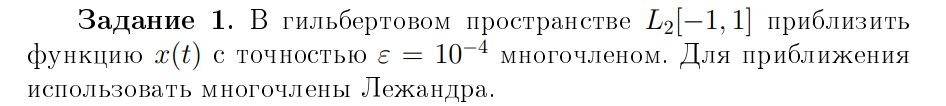
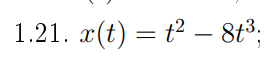

N = 3
eps_n^2 = -3.552714e-15
eps_n = 0.000000e+00


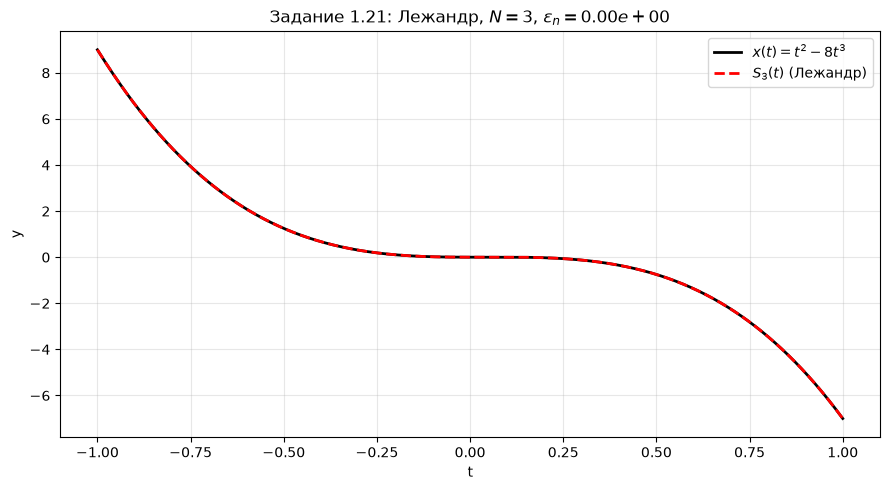

In [19]:
import numpy as np
from scipy.integrate import quad
from scipy.special import eval_legendre
from numpy.polynomial.legendre import Legendre
import matplotlib.pyplot as plt

def x(t):
    return t**2 - 8.0*t**3

eps = 1e-4
norm2 = quad(lambda t: x(t)**2, -1.0, 1.0, epsabs=1e-12, epsrel=1e-12)[0]

C = []
n = None
err2 = None
for k in range(0, 20):
    val = quad(lambda t: x(t)*eval_legendre(k, t), -1.0, 1.0,
               epsabs=1e-12, epsrel=1e-12)[0]
    C.append((2*k + 1) / 2.0 * val)
    err2 = norm2 - sum(2.0/(2*j + 1)*C[j]**2 for j in range(k + 1))
    if err2 <= eps**2:
        n = k
        break

S = Legendre(C[:n+1]).convert(kind=np.polynomial.Polynomial)

print(f"N = {n}")
print(f"eps_n^2 = {err2:.6e}")
print(f"eps_n = {np.sqrt(max(err2,0)):.6e}")

t = np.linspace(-1, 1, 1000)
plt.figure(figsize=(9, 5))
plt.plot(t, x(t), 'k-', lw=2, label=r'$x(t)=t^2-8t^3$')
plt.plot(t, S(t), 'r--', lw=2, label=fr'$S_{{{n}}}(t)$ (Лежандр)')
plt.title(fr'Задание 1.21: Лежандр, $N={n}$, $\varepsilon_n={np.sqrt(max(err2,0)):.2e}$')
plt.xlabel('t'); plt.ylabel('y')
plt.grid(True, alpha=0.3);
plt.legend(); 
plt.show()

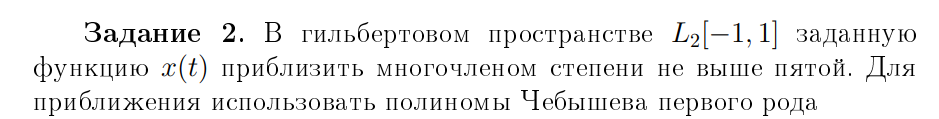
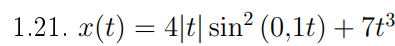

N = 5
eps_N^2  = 1.808725e-07
eps_N = 4.252911e-04


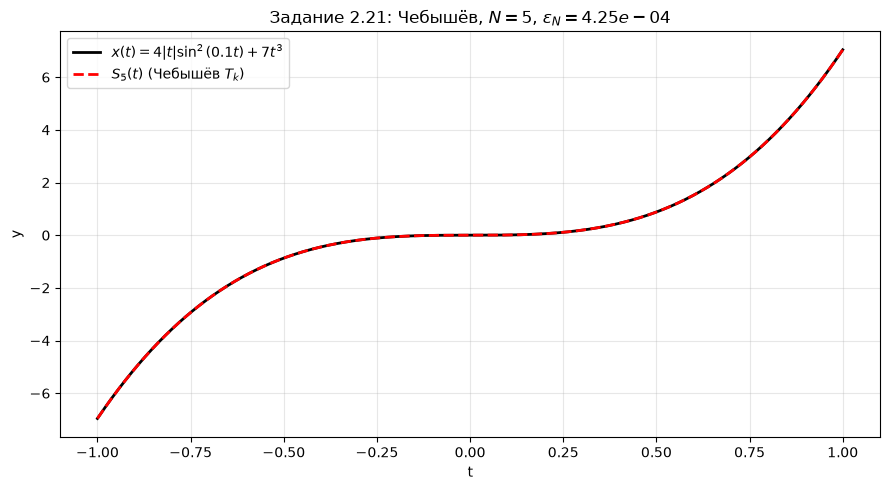

In [23]:
import numpy as np
from scipy.integrate import quad
from numpy.polynomial.chebyshev import Chebyshev
import matplotlib.pyplot as plt

def x(t):
    return 4.0*np.abs(t)*np.sin(0.1*t)**2 + 7.0*t**3

N = 5

C0 = 1.0/np.pi * quad(lambda th: x(np.cos(th)), 0, np.pi,
                      points=[np.pi/2], epsabs=1e-12, epsrel=1e-12)[0]
C = [C0]
for k in range(1, N + 1):
    val = quad(lambda th: x(np.cos(th))*np.cos(k*th), 0, np.pi,
               points=[np.pi/2], epsabs=1e-12, epsrel=1e-12)[0]
    C.append(2.0/np.pi * val)

S = Chebyshev(C)

err2 = quad(lambda t: (x(t) - S(t))**2 / np.sqrt(1 - t*t),
            -1.0, 1.0, points=[0.0],
            epsabs=1e-10, epsrel=1e-10)[0]

print(f"N = {N}")
print(f"eps_N^2  = {err2:.6e}")
print(f"eps_N = {np.sqrt(max(err2,0)):.6e}")

t = np.linspace(-1, 1, 1000)
plt.figure(figsize=(9, 5))
plt.plot(t, x(t), 'k-', lw=2, label=r'$x(t)=4|t|\sin^2(0.1t)+7t^3$')
plt.plot(t, S(t), 'r--', lw=2, label=fr'$S_{{{N}}}(t)$ (Чебышёв $T_k$)')
plt.title(fr'Задание 2.21: Чебышёв, $N={N}$, $\varepsilon_N={np.sqrt(max(err2,0)):.2e}$')
plt.xlabel('t'); plt.ylabel('y')
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig('task2_21.png', dpi=150)
plt.show()

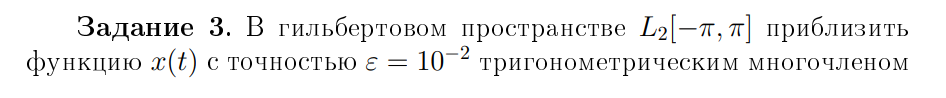
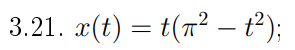

N = 16
eps_N^2 = 7.364376e-05
eps_N = 8.581594e-03
eps_N = 8.581594e-03


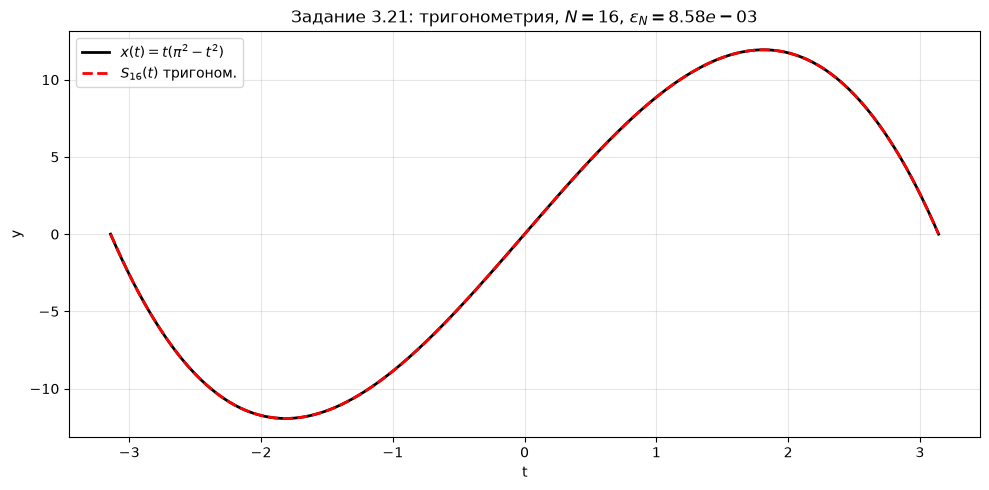

In [24]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

def x(t):
    return t*(np.pi**2 - t**2)

eps = 1e-2
zeta6 = np.pi**6 / 945.0

n = 0
while True:
    tail = zeta6 - sum(1.0/k**6 for k in range(1, n + 1))
    err2 = np.pi * 144.0 * tail
    if err2 <= eps**2:
        break
    n += 1

b = [12.0*(-1)**(k + 1)/k**3 for k in range(1, n + 1)]

def S(t):
    t = np.asarray(t, dtype=float)
    res = np.zeros_like(t)
    for k, bk in enumerate(b, start=1):
        res = res + bk*np.sin(k*t)
    return res

err2_actual = quad(lambda t: (x(t) - S(t))**2, -np.pi, np.pi,
                   epsabs=1e-10, epsrel=1e-10, limit=300)[0]

print(f"N = {n}")
print(f"eps_N^2 = {err2:.6e}")
print(f"eps_N = {np.sqrt(max(err2,0)):.6e}")
print(f"eps_N = {np.sqrt(max(err2_actual,0)):.6e}")

t = np.linspace(-np.pi, np.pi, 2000)
plt.figure(figsize=(10, 5))
plt.plot(t, x(t), 'k-', lw=2, label=r'$x(t)=t(\pi^2-t^2)$')
plt.plot(t, S(t), 'r--', lw=2, label=fr'$S_{{{n}}}(t)$ тригоном.')
plt.title(fr'Задание 3.21: тригонометрия, $N={n}$, $\varepsilon_N={np.sqrt(max(err2,0)):.2e}$')
plt.xlabel('t'); plt.ylabel('y')
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig('task3_21.png', dpi=150)
plt.show()

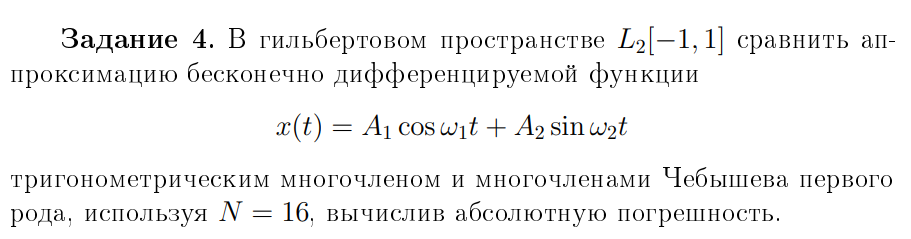
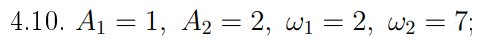

N = 16

Тригонометрический многочлен S_N^(1):
  eps_N (L2)  = 2.071918e-01
  max |x-S_N| = 1.336312e+00

Многочлен Чебышёва S_N^(2):
  eps_N (L2)  = 1.016424e-05
  max |x-S_N| = 1.036689e-05


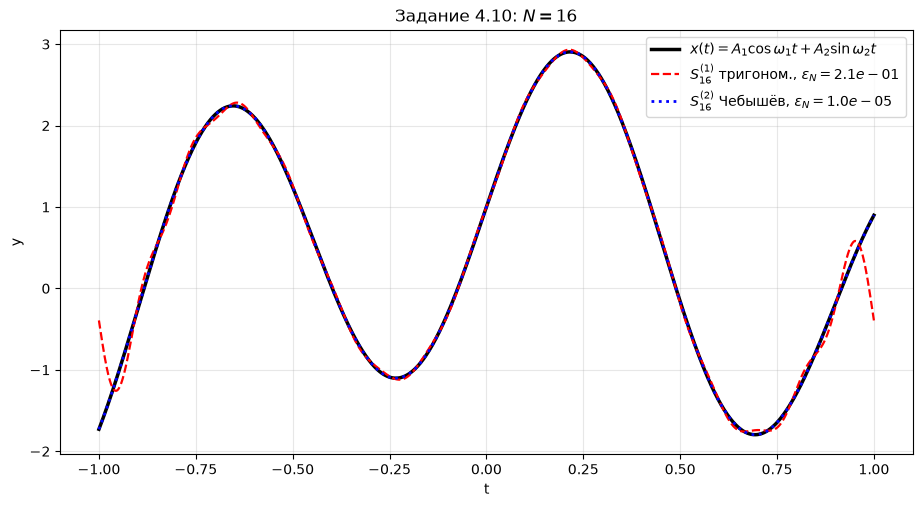

In [26]:
import numpy as np
from scipy.integrate import quad
from numpy.polynomial.chebyshev import chebval
import matplotlib.pyplot as plt

A1, A2 = 1.0, 2.0
w1, w2 = 2.0, 7.0
N = 16

def x(t):
    return A1*np.cos(w1*t) + A2*np.sin(w2*t)

# --- (1) Тригонометрический многочлен на [-1,1] ---
a = np.zeros(N + 1); b = np.zeros(N + 1)
a[0] = quad(lambda t: x(t), -1, 1, epsabs=1e-12, epsrel=1e-12, limit=400)[0]
for k in range(1, N + 1):
    a[k] = quad(lambda t: x(t)*np.cos(k*np.pi*t), -1, 1,
                epsabs=1e-12, epsrel=1e-12, limit=400)[0]
    b[k] = quad(lambda t: x(t)*np.sin(k*np.pi*t), -1, 1,
                epsabs=1e-12, epsrel=1e-12, limit=400)[0]

def S_trig(t):
    t = np.asarray(t, dtype=float)
    res = a[0]/2.0 + np.zeros_like(t)
    for k in range(1, N + 1):
        res = res + a[k]*np.cos(k*np.pi*t) + b[k]*np.sin(k*np.pi*t)
    return res

# --- (2) Чебышёв 1-го рода ---
C0 = 1.0/np.pi * quad(lambda th: x(np.cos(th)), 0, np.pi,
                      epsabs=1e-12, epsrel=1e-12, limit=400)[0]
C = [C0]
for k in range(1, N + 1):
    val = quad(lambda th: x(np.cos(th))*np.cos(k*th), 0, np.pi,
               epsabs=1e-12, epsrel=1e-12, limit=400)[0]
    C.append(2.0/np.pi * val)

def S_cheb(t):
    return chebval(t, C)

# --- Погрешности ---
def L2_error(S):
    return np.sqrt(quad(lambda t: (x(t) - S(t))**2, -1, 1,
                        epsabs=1e-10, epsrel=1e-10, limit=400)[0])

l2_trig = L2_error(S_trig)
l2_cheb = L2_error(S_cheb)
tgrid = np.linspace(-1, 1, 40001)
max_trig = np.max(np.abs(x(tgrid) - S_trig(tgrid)))
max_cheb = np.max(np.abs(x(tgrid) - S_cheb(tgrid)))

print(f"N = {N}")
print()
print("Тригонометрический многочлен S_N^(1):")
print(f"  eps_N (L2)  = {l2_trig:.6e}")
print(f"  max |x-S_N| = {max_trig:.6e}")
print()
print("Многочлен Чебышёва S_N^(2):")
print(f"  eps_N (L2)  = {l2_cheb:.6e}")
print(f"  max |x-S_N| = {max_cheb:.6e}")

t = np.linspace(-1, 1, 2000)
plt.figure(figsize=(11, 5.5))
plt.plot(t, x(t), 'k-', lw=2.5,
         label=r'$x(t)=A_1\cos\omega_1 t + A_2\sin\omega_2 t$')
plt.plot(t, S_trig(t), 'r--', lw=1.6,
         label=fr'$S_{{{N}}}^{{(1)}}$ тригоном., $\varepsilon_N={l2_trig:.1e}$')
plt.plot(t, S_cheb(t), 'b:', lw=2.0,
         label=fr'$S_{{{N}}}^{{(2)}}$ Чебышёв, $\varepsilon_N={l2_cheb:.1e}$')
plt.title(fr'Задание 4.10: $N={N}$')
plt.xlabel('t'); plt.ylabel('y')
plt.grid(True, alpha=0.3); 
plt.legend();
plt.show()